#### CARTPOLE Rainbow leanring curve

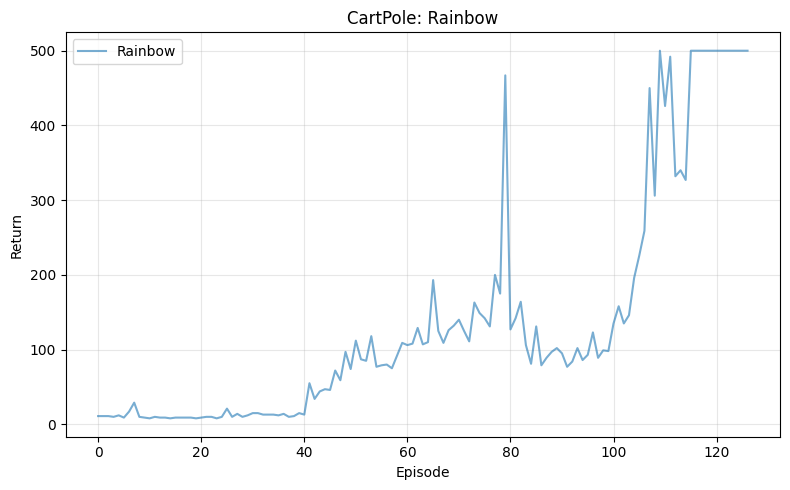

In [7]:
import os
import torch
import matplotlib.pyplot as plt

# ---------------------------
# Setup
# ---------------------------
PROJECT_ROOT = "/Users/richardfisher/Desktop/projects/RainbowDQNAgent"
os.chdir(PROJECT_ROOT)

# ---------------------------
# Load Rainbow rewards
# ---------------------------
rainbow_rewards = torch.load(
    "models/CartPole/Rainbow/two.pth",
    map_location="cpu",
    weights_only=False
)["reward_history"]

# ---------------------------
# Plot (single figure)
# ---------------------------
plt.figure(figsize=(8, 5))
plt.plot(rainbow_rewards, alpha=0.6, label="Rainbow")
plt.title("CartPole: Rainbow")
plt.xlabel("Episode")
plt.ylabel("Return")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


#### CARTPOLE Training variance in Performance

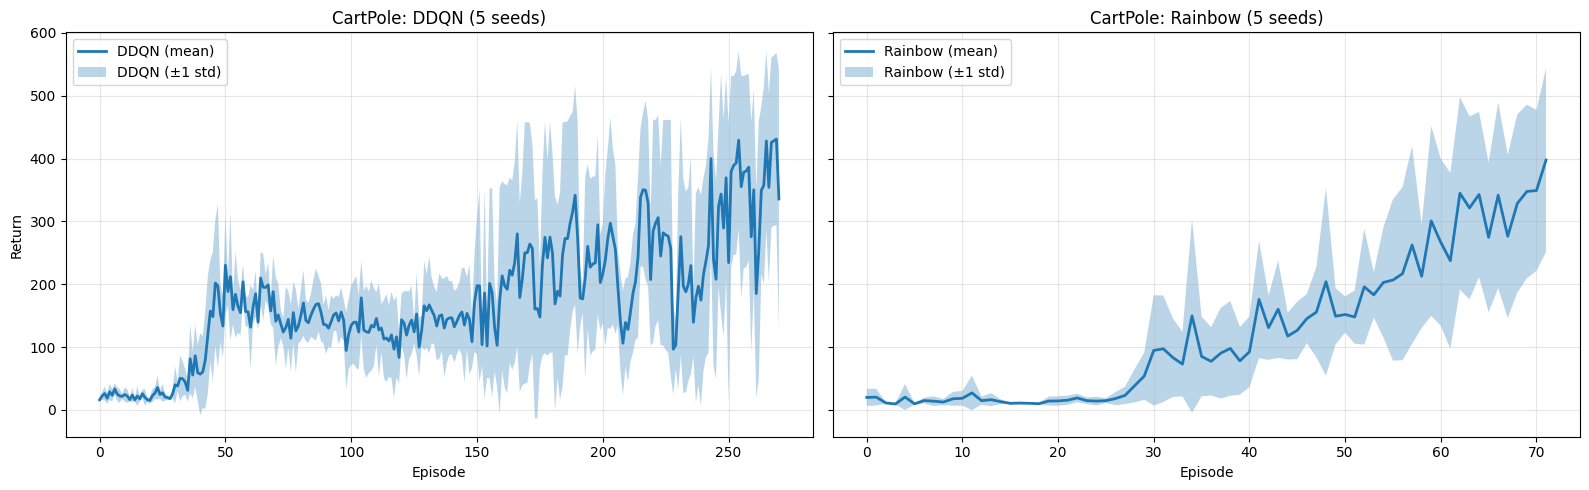

In [8]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------
# Setup
# ---------------------------
PROJECT_ROOT = "/Users/richardfisher/Desktop/projects/RainbowDQNAgent"
os.chdir(PROJECT_ROOT)

DDQN_DIR = "models/CartPole/DDQN"
RAINBOW_DIR = "models/CartPole/Rainbow"
seed_files = ["one.pth", "two.pth", "three.pth", "four.pth", "five.pth"]

# ---------------------------
# Helper to load runs
# ---------------------------
def load_runs(base_dir, files):
    runs = []
    for f in files:
        ckpt = torch.load(
            os.path.join(base_dir, f),
            map_location="cpu",
            weights_only=False
        )
        runs.append(np.array(ckpt["reward_history"]))
    return runs

# ---------------------------
# Load data
# ---------------------------
ddqn_runs = load_runs(DDQN_DIR, seed_files)
rainbow_runs = load_runs(RAINBOW_DIR, seed_files)

# ---------------------------
# Align lengths (per algorithm)
# ---------------------------
min_len_ddqn = min(len(r) for r in ddqn_runs)
min_len_rainbow = min(len(r) for r in rainbow_runs)

ddqn_runs = np.array([r[:min_len_ddqn] for r in ddqn_runs])
rainbow_runs = np.array([r[:min_len_rainbow] for r in rainbow_runs])

# ---------------------------
# Statistics
# ---------------------------
ddqn_mean = ddqn_runs.mean(axis=0)
ddqn_std = ddqn_runs.std(axis=0)
ddqn_eps = np.arange(min_len_ddqn)

rainbow_mean = rainbow_runs.mean(axis=0)
rainbow_std = rainbow_runs.std(axis=0)
rainbow_eps = np.arange(min_len_rainbow)

# ---------------------------
# Plot (horizontal layout)
# ---------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

# ---- DDQN (left) ----
axes[0].plot(ddqn_eps, ddqn_mean, linewidth=2, label="DDQN (mean)")
axes[0].fill_between(
    ddqn_eps,
    ddqn_mean - ddqn_std,
    ddqn_mean + ddqn_std,
    alpha=0.3,
    label="DDQN (±1 std)"
)
axes[0].set_title("CartPole: DDQN (5 seeds)")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Return")
axes[0].grid(alpha=0.3)
axes[0].legend()

# ---- Rainbow (right) ----
axes[1].plot(rainbow_eps, rainbow_mean, linewidth=2, label="Rainbow (mean)")
axes[1].fill_between(
    rainbow_eps,
    rainbow_mean - rainbow_std,
    rainbow_mean + rainbow_std,
    alpha=0.3,
    label="Rainbow (±1 std)"
)
axes[1].set_title("CartPole: Rainbow (5 seeds)")
axes[1].set_xlabel("Episode")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


#### LunarLander hard learning curves 

/var/folders/20/ppt5x9mx23d4ly2t0t4mx3t00000gp/T/ipykernel_39378/3430143680.py:24: RuntimeWarning: invalid value encountered in divide
  return num / den


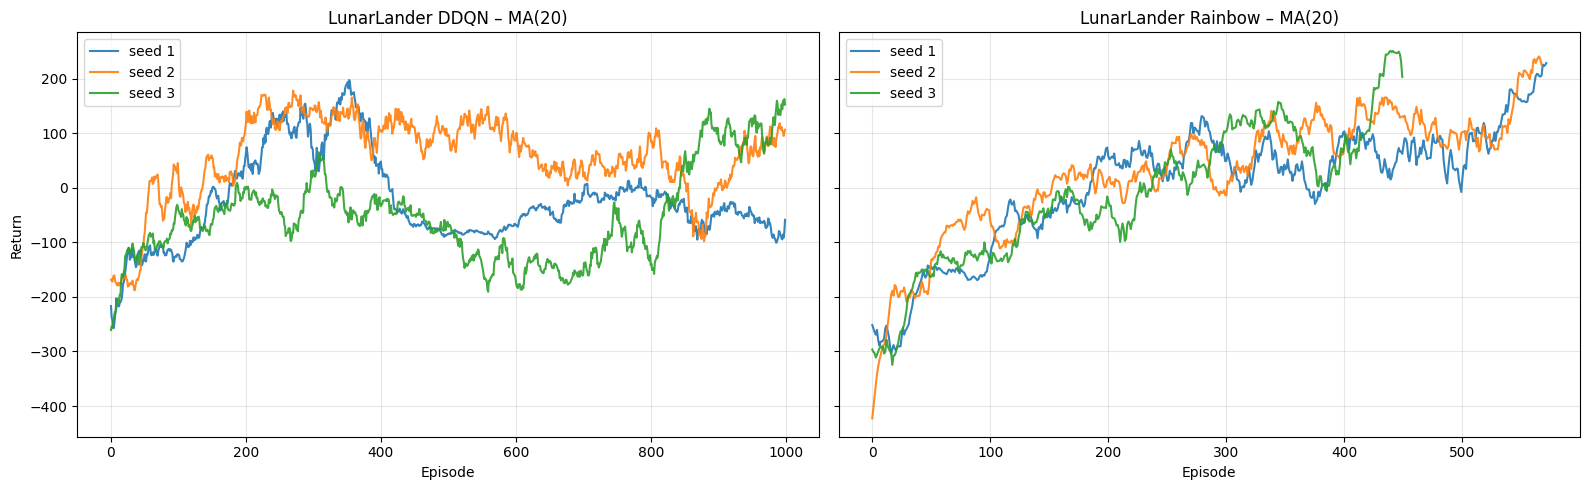

In [10]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import os

PROJECT_ROOT = "/Users/richardfisher/Desktop/projects/RainbowDQNAgent"
os.chdir(PROJECT_ROOT)

DDQN_FILES = [
    "models/Lunarlander_hard/DDQN/one.pth",
    "models/Lunarlander_hard/DDQN/two.pth",
    "models/Lunarlander_hard/DDQN/three.pth",
]

RAINBOW_FILES = [
    "models/Lunarlander_hard/Rainbow/one.pth",
    "models/Lunarlander_hard/Rainbow/two.pth",
    "models/Lunarlander_hard/Rainbow/three.pth",
]

def moving_average_nan(x, window=20):
    num = np.convolve(np.nan_to_num(x), np.ones(window), mode="same")
    den = np.convolve(~np.isnan(x), np.ones(window), mode="same")
    return num / den

def load_padded_runs(files):
    runs = []
    max_len = 0
    for f in files:
        ckpt = torch.load(f, map_location="cpu", weights_only=False)
        r = np.array([float(d["return"]) for d in ckpt["reward_history"]])
        runs.append(r)
        max_len = max(max_len, len(r))

    padded = []
    for r in runs:
        p = np.full(max_len, np.nan)
        p[:len(r)] = r
        padded.append(p)

    return padded

ddqn_runs = load_padded_runs(DDQN_FILES)
rain_runs = load_padded_runs(RAINBOW_FILES)

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

# ---- DDQN ----
for i, run in enumerate(ddqn_runs):
    axes[0].plot(
        moving_average_nan(run, 20),
        label=f"seed {i+1}",
        alpha=0.9
    )
axes[0].set_title("LunarLander DDQN – MA(20)")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Return")
axes[0].grid(alpha=0.3)
axes[0].legend()

# ---- Rainbow ----
for i, run in enumerate(rain_runs):
    axes[1].plot(
        moving_average_nan(run, 20),
        label=f"seed {i+1}",
        alpha=0.9
    )
axes[1].set_title("LunarLander Rainbow – MA(20)")
axes[1].set_xlabel("Episode")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()
